# 03b — Clustering (tipología de condiciones)

Este cuaderno **mide, no decide**: reporta todos los k=2–12 y deja la elección al cuaderno siguiente (03e).
Regla de este bloque: `clc_class` (nominal) queda fuera de las distancias y vive en perfiles; `franja_horaria` entra codificada ordinalmente (`encode_franja_horaria`).

Recordatorio de las features:
- `features_a.csv` (7: PCs del clima)
- `features_b.csv` (12: + estacionalidad y hora)
- `features_c.csv` (25: + suelo)
- `perfilado.csv` (31: satélite, presupuestos, índices)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, fcluster
from sklearn.metrics import normalized_mutual_info_score
from sklearn.preprocessing import StandardScaler
from wildfire.data.io import load_csv, save_csv
from wildfire.processing.unsupervised import (
    ENTRADA_A, ENTRADA_B, ENTRADA_C_FIXED, PERFILADO,
    assert_feature_sets_clean, distance_columns, encode_franja_horaria,
    fit_gmm_range, fit_kmeans_range, gmm_bic_table, load_min_cliff_delta,
    max_pairwise_cliffs_delta, negative_control_partitions,
    resolve_set, sample_frame, ward_linkage,
)

*`full` bajo `diag` en todo k; mínimo `full` en k=12 (borde del rango, 03e valora si ampliar).*

## 03b.1 — Carga y escalado descriptivo

Se cargan `features_a/b/c.csv` y el perfilado, se codifica `franja_horaria` a ordinal en B y C, y se recorta cada conjunto a columnas numéricas —`clc_class` sale de las distancias y vive en los perfiles—. Después se estandariza cada conjunto por separado: es un escalado descriptivo (plan §4 regla 3) que no se reutiliza para modelar.

Cómo leer la salida `a: crudo (filas, columnas) (todas numéricas: True)`: forma sin escalar y comprobación de que KMeans/GMM reciben solo números (con texto fallarían en silencio o a lo bruto).

In [2]:
sets_raw = {
    name: load_csv(f"data/processed/unsupervised/features_{name}.csv")
    for name in ("a", "b", "c")
}
perfilado = load_csv("data/processed/unsupervised/perfilado.csv")
frp = perfilado["frp"].to_numpy()
sets_raw["b"] = encode_franja_horaria(sets_raw["b"])
sets_raw["c"] = encode_franja_horaria(sets_raw["c"])
inputs = {
    "a": sets_raw["a"],
    "b": sets_raw["b"],
    "c": resolve_set(sets_raw["c"], distance_columns([c for c in sets_raw["c"].columns]), "C"),
}
X = {name: pd.DataFrame(StandardScaler().fit_transform(frame), columns=frame.columns, index=frame.index)
     for name, frame in inputs.items()}
for _name, _frame in inputs.items():
    print(f"{_name}: crudo {_frame.shape} (todas numéricas: {all(pd.api.types.is_numeric_dtype(t) for t in _frame.dtypes)})")


a: crudo (30412, 7) (todas numéricas: True)
b: crudo (30412, 12) (todas numéricas: True)
c: crudo (30412, 24) (todas numéricas: True)


## 03b.2 — KMeans k=2–12 (línea base)

Se ajusta KMeans para cada k y se guardan las etiquetas en ancho (columnas `k_2`…`k_12`, índice común) en `clustering_kmeans_{a,b,c}.csv`.

Cómo leer cada tabla (una por conjunto a/b/c):
- `inertia`: suma de distancias al centroide; siempre baja al subir k. Se busca el *codo* (donde deja de compensar añadir grupos), no el mínimo.
- `silhouette` (−1…1): cohesión dentro del grupo frente a separación. ~0,2 es bajo pero esperado: condiciones continuas sin fronteras nítidas (plan §6.1).
- `calinski_harabasz`: más alto = grupos más densos y separados (dispersión entre/dentro).
- `davies_bouldin`: más bajo = mejor (similitud media entre cada grupo y su vecino más parecido).
Ninguna decide k por sí sola: 03e cruza las cuatro + estabilidad + severidad.

In [3]:
kmeans_labels, kmeans_metrics = {}, {}
for _name, _X in X.items():
    _lab, _met = fit_kmeans_range(_X)
    kmeans_labels[_name], kmeans_metrics[_name] = _lab, _met
    display(_met.round(3))
    save_csv(pd.DataFrame({f"k_{k}": v for k, v in _lab.items()}, index=_X.index),
             f"data/processed/unsupervised/clustering_kmeans_{_name}.csv")
print("Etiquetas KMeans guardadas.")

,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,187640.533,0.142,4091.228,2.460
3,168665.885,0.154,3986.074,2.097
4,146251.139,0.157,4618.046,1.646
5,131870.827,0.174,4670.083,1.528
6,119035.726,0.192,4794.452,1.419
7,109411.423,0.203,4792.466,1.334
8,100554.446,0.211,4852.075,1.265
9,93500.838,0.212,4852.385,1.271
10,88214.067,0.216,4774.029,1.253


,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,291688.454,0.211,7637.265,1.901
3,260865.315,0.201,6066.213,1.796
4,234104.665,0.197,5664.935,1.736
5,213449.367,0.193,5395.308,1.568
6,196011.325,0.198,5241.096,1.520
7,177160.285,0.217,5371.374,1.441
8,169226.770,0.206,5023.347,1.474
9,161908.597,0.195,4765.741,1.492
10,154787.006,0.193,4586.377,1.512


,inertia,silhouette,calinski_harabasz,davies_bouldin
k,,,,
2,652105.753,0.126,3627.265,2.697
3,618770.163,0.108,2730.416,2.640
4,587545.011,0.114,2455.630,2.441
5,560635.785,0.132,2294.921,2.379
6,532425.588,0.147,2255.356,2.287
7,504483.994,0.174,2264.167,2.153
8,482836.085,0.153,2222.395,1.927
9,454228.397,0.182,2306.351,1.810
10,432063.754,0.186,2328.479,1.695


Etiquetas KMeans guardadas.


*En este run: silhouette máxima en k=2 (A 0,254 / B 0,224 / C 0,154), sin codo nítido — 03e cruza las cuatro métricas.*

## 03b.3 — GMM full/diag por BIC (pertenencia suave)

Se ajustan mezclas gaussianas para cada (k, covarianza) y se guardan las etiquetas; las probabilidades de pertenencia, más honestas que la etiqueta dura cuando los regímenes se solapan, se guardan además en `cluster_labels.csv` para que las use 03e: etiquetas duras KMeans/GMM y columnas `gmm_{conjunto}_k5_{cov}_p{j}` (suman 1 por fila) al k=5 ilustrativo de todo el bloque, con ambas covarianzas — si 03e elige otro k, re-ajusta allí.

Cómo leer cada tabla BIC (una por conjunto): filas = k, columnas = tipo de covarianza. Menor BIC = mejor equilibrio entre ajuste y complejidad (penaliza parámetros de más).
- `full`: elipses orientadas (captura correlaciones, p. ej. calor–sequedad de PC1).
- `diag`: ejes alineados (menos parámetros, supone variables independientes).
Con las 14 crudas `full` ganaba de largo porque las meteorológicas están correlacionadas; con los PCs —decorrelacionados *globalmente* por construcción— `full` sigue ganando en los tres conjuntos y a todo k: dentro de cada régimen las nubes siguen siendo elipses orientadas, que es justo lo que captura la covarianza completa.


In [4]:
gmm_results, gmm_bics = {}, {}
for _name, _X in X.items():
    _res = fit_gmm_range(_X)
    gmm_results[_name] = _res
    _bic = gmm_bic_table(_res)
    gmm_bics[_name] = _bic
    display(_bic.round(0))
    save_csv(pd.DataFrame({f"k_{k}_{cov}": r["labels"] for (k, cov), r in _res.items()}, index=_X.index),
             f"data/processed/unsupervised/clustering_gmm_{_name}.csv")
print("Etiquetas GMM guardadas.")

_k_ilus = 5  # k ilustrativo del bloque (sonda ARI de 03a, mapas de 03b.7); el definitivo lo decide 03e
cluster_labels = pd.DataFrame(index=X["a"].index)
for _sname in ("a", "b", "c"):
    cluster_labels[f"kmeans_{_sname}_k{_k_ilus}"] = kmeans_labels[_sname][_k_ilus]
    for _cov in ("full", "diag"):
        _res = gmm_results[_sname][(_k_ilus, _cov)]
        cluster_labels[f"gmm_{_sname}_k{_k_ilus}_{_cov}"] = _res["labels"]
        cluster_labels[[f"gmm_{_sname}_k{_k_ilus}_{_cov}_p{_j}" for _j in range(_k_ilus)]] = _res["proba"]
save_csv(cluster_labels, "data/processed/unsupervised/cluster_labels.csv")
print(f"cluster_labels.csv: {cluster_labels.shape} (etiquetas duras + probabilidades GMM, k={_k_ilus})")


covariance,diag,full
k,,
2,570219.0,455807.0
3,560206.0,433008.0
4,547445.0,417708.0
5,538981.0,397091.0
6,529251.0,382521.0
7,515057.0,370515.0
8,505211.0,366637.0
9,503872.0,360222.0
10,492347.0,344544.0


covariance,diag,full
k,,
2,917079.0,577243.0
3,831650.0,432241.0
4,808407.0,384298.0
5,716502.0,370942.0
6,554074.0,236145.0
7,498899.0,185968.0
8,461674.0,216150.0
9,421064.0,88185.0
10,356708.0,65316.0


covariance,diag,full
k,,
2,1236518.0,464994.0
3,284492.0,-318000.0
4,-11534.0,-829657.0
5,-257842.0,-1158317.0
6,-974991.0,-1497260.0
7,-1185535.0,-1500370.0
8,-1327556.0,-1777366.0
9,-1615258.0,-1917382.0
10,-1593335.0,-1953436.0


Etiquetas GMM guardadas.


cluster_labels.csv: (30412, 39) (etiquetas duras + probabilidades GMM, k=5)


## 03b.4 — Ward sobre muestra de 5.000 (estimación independiente de k)

Un jerárquico aglomerativo, que no pide k por adelantado, sobre una muestra determinista; la matriz de linkage se guarda en `ward_linkage_a.csv`.

Cómo leer la salida:
- `Últimas 5 fusiones (dist, tamaño)`: a qué distancia se unen dos ramas y cuántos puntos suma la rama resultante. Un salto grande entre fusiones marca un corte natural candidato: lo que se une a una distancia muy superior a las fusiones previas estaba muy separado. En esta corrida las últimas fusiones escalan suave (~56→79), sin salto dramático: Ward no ve un corte evidente, y eso también es información para 03e.
- Dendrograma truncado a 20 ramas: la altura de cada unión = disimilitud de fusión; ramas que se unen abajo son parecidas, las que suben hasta arriba son regímenes distintos. Si el corte natural discrepa de BIC/codo, 03e lo recoge.

Últimas 5 fusiones (dist, tamaño):
[[  56.02692447 1248.        ]
 [  66.37031129 2178.        ]
 [  69.42073851 1257.        ]
 [  75.19370574 3435.        ]
 [  79.0923506  5000.        ]]


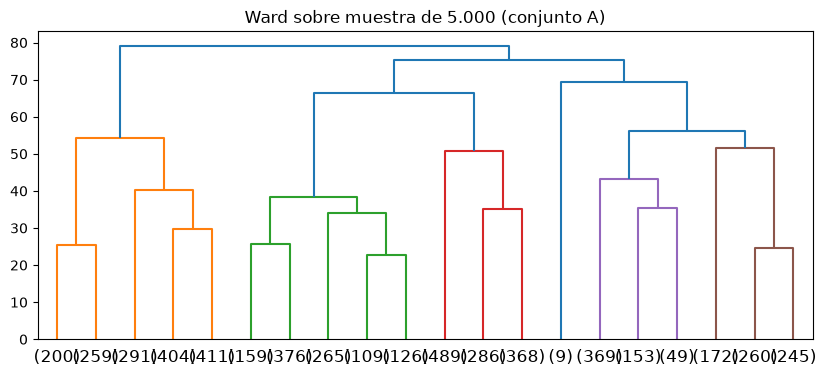

In [5]:
_sample = sample_frame(X["a"], 5_000)
_Z = ward_linkage(_sample)
save_csv(pd.DataFrame(_Z, columns=["a", "b", "dist", "n"]),
         "data/processed/unsupervised/ward_linkage_a.csv")
print("Últimas 5 fusiones (dist, tamaño):")
print(_Z[-5:, 2:])
fig, ax = plt.subplots(figsize=(10, 4))
dendrogram(_Z, truncate_mode="lastp", p=20, ax=ax)
ax.set_title("Ward sobre muestra de 5.000 (conjunto A)")
plt.show()

## 03b.5 — Controles negativos + separación de severidad (medición §7B)

Primero las particiones tontas —mes (12 grupos) y CCAA (17)— como listón a batir; después, para cada (conjunto, k), la mayor |δ de Cliff| entre pares de grupos sobre `frp`. Todo queda en `severidad_kmeans.csv`.

Cómo leer la tabla:
- `max_abs_delta` (0…1): 0 = los dos grupos arden igual; 1 = uno siempre más virulento. Regla intuitiva: (1+δ)/2 = probabilidad de que una detección al azar del grupo fiero supere a una del manso.
- `par`: qué dos grupos marcan el máximo (etiquetas internas, sin significado físico).
- Filas `control_ccaa` (0,708) y `control_month` (0,362): el listón. La candidata tiene que superarlas *sin ser ellas* (eso lo comprueba la NMI de 03b.6).
- El umbral `unsupervised.min_cliff_delta` se imprime como referencia; lo aplica 03e, aquí solo se mide.

In [6]:
_controls = negative_control_partitions(perfilado)
_rows = []
for _cname, _clab in _controls.items():
    _d, _pair = max_pairwise_cliffs_delta(frp, _clab)
    _rows.append({"conjunto": f"control_{_cname}", "k": len(set(_clab.tolist())),
                  "max_abs_delta": abs(_d), "par": str(_pair)})
for _sname, _lab in kmeans_labels.items():
    for _k, _v in _lab.items():
        _d, _pair = max_pairwise_cliffs_delta(frp, _v)
        _rows.append({"conjunto": f"kmeans_{_sname}", "k": _k,
                      "max_abs_delta": abs(_d), "par": str(_pair)})
severity = pd.DataFrame(_rows).sort_values(["conjunto", "k"]).reset_index(drop=True)
display(severity.round(3))
print(f"Umbral §7B (solo referencia, decide 03e): {load_min_cliff_delta()}")
save_csv(severity, "data/processed/unsupervised/severidad_kmeans.csv")

,conjunto,k,max_abs_delta,par
0,control_ccaa,17,0.708,"(14, 15)"
1,control_month,12,0.362,"(7, 10)"
2,kmeans_a,2,0.089,"(0, 1)"
3,kmeans_a,3,0.157,"(0, 1)"
4,kmeans_a,4,0.610,"(0, 3)"
5,kmeans_a,5,0.693,"(0, 3)"
6,kmeans_a,6,0.701,"(3, 5)"
7,kmeans_a,7,0.692,"(3, 4)"
8,kmeans_a,8,0.759,"(1, 4)"
9,kmeans_a,9,0.798,"(0, 4)"


Umbral §7B (solo referencia, decide 03e): 0.2


WindowsPath('C:/Projects/wildfires-project/data/processed/unsupervised/severidad_kmeans.csv')

*Mejor KMeans: A/k=12 (0,847) sobre CCAA (0,708) y mes (0,362) — 03e comprueba tamaños de grupo antes de creérselo.*

## 03b.6 — Perfiles e información mutua (medición, sin interpretar)

Medias por grupo en unidades originales (ºC, m/s, …) en `perfiles_kmeans_{a,b,c}.csv`, para describir 'cómo es' cada grupo sin hablar en z-scores; y NMI de cada partición contra `ccaa` y `month` en `nmi_kmeans.csv`.

Cómo leer las salidas:
- Tabla NMI: 0 = la partición no sabe nada de esa variable; > 0,5 = el grupo *es* esa variable (p. ej. redescubrió el calendario) y la candidata queda descalificada en 03e.
- `n_grupos`: comprobación de cordura — debe haber exactamente k grupos no vacíos por k (si KMeans devolviera grupos vacíos, algo iría mal).

In [7]:
profiles = {}
nmi_rows = []
for _sname, _lab in kmeans_labels.items():
    _raw = inputs[_sname]
    _frames = []
    for _k, _v in _lab.items():
        _m = _raw.groupby(_v).mean()
        _m["k"] = _k
        _m["grupo"] = _m.index
        _frames.append(_m.reset_index(drop=True))
        for _col in ("ccaa", "month"):
            nmi_rows.append({"conjunto": f"kmeans_{_sname}", "k": _k, "variable": _col,
                            "nmi": normalized_mutual_info_score(_v, perfilado[_col].astype(str))})
    profiles[_sname] = pd.concat(_frames, ignore_index=True)
    save_csv(profiles[_sname], f"data/processed/unsupervised/perfiles_kmeans_{_sname}.csv")
nmi = pd.DataFrame(nmi_rows)
display(nmi.round(3))
save_csv(nmi, "data/processed/unsupervised/nmi_kmeans.csv")
display(profiles["a"].groupby("k").size().rename("n_grupos"))

,conjunto,k,variable,nmi
0,kmeans_a,2,ccaa,0.047
1,kmeans_a,2,month,0.043
2,kmeans_a,3,ccaa,0.074
3,kmeans_a,3,month,0.054
4,kmeans_a,4,ccaa,0.075
...,...,...,...,...
61,kmeans_c,10,month,0.145
62,kmeans_c,11,ccaa,0.145
63,kmeans_c,11,month,0.163
64,kmeans_c,12,ccaa,0.146


k
2      2
3      3
4      4
5      5
6      6
7      7
8      8
9      9
10    10
11    11
12    12
Name: n_grupos, dtype: int64

*Máximo 0,412 (B vs estacionalidad): ningún grupo ES mes ni CCAA.*

## 03b.7 — Mapas y mezcla por CCAA con k=5 (ilustrativo)

Para cerrar, dónde cae cada grupo con k=5 (el mismo k de la sonda ARI de 03a) y el cruce grupos × CCAA. Es ilustrativo —el k final lo decide 03e—, pero ya permite olfatear artefactos.

Cómo leer las salidas:
- Mapas: cada punto es una detección coloreada por grupo. Si un color ocupa una sola zona (p. ej. todo el noroeste), ese 'régimen meteorológico' es geografía disfrazada.
- Tabla de mezcla (filas = grupos, columnas = CCAA, filas suman 1): proporción de cada grupo en cada comunidad. Ejemplo de lectura: un grupo con 0,52 en Asturias + 0,17 en Cantabria es mayoritariamente quema norteña de invierno, no un régimen estatal.

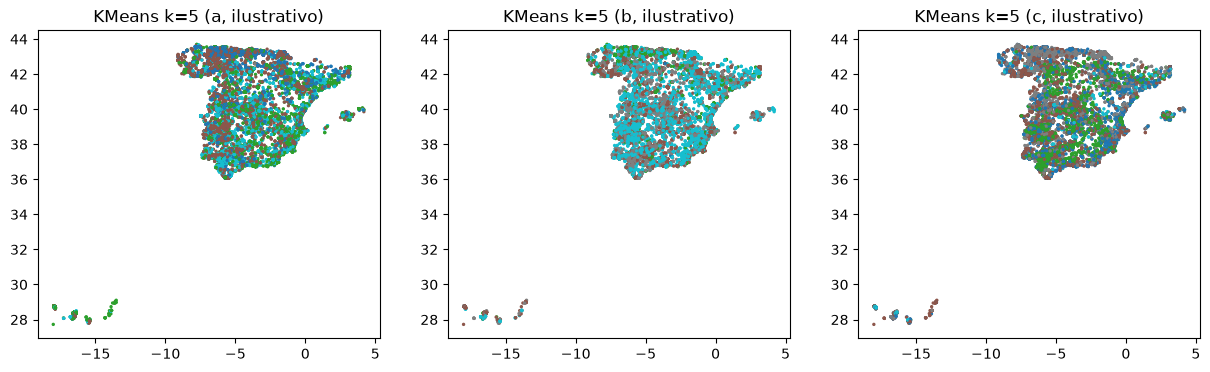

ccaa,Andalucía,Aragón,Asturias,Canarias,Cantabria,Castilla y León,Castilla-La Mancha,Cataluña,Comunidad Valenciana,Extremadura,Galicia,Islas Baleares,La Rioja,Madrid,Navarra,País Vasco,Región de Murcia
row_0,,,,,,,,,,,,,,,,,
0,0.04,0.02,0.52,0.00,0.17,0.08,0.02,0.02,0.01,0.02,0.03,0.00,0.00,0.00,0.03,0.01,0.00
1,0.16,0.05,0.06,0.18,0.01,0.04,0.08,0.06,0.11,0.19,0.01,0.01,0.00,0.00,0.01,0.00,0.03
2,0.12,0.04,0.08,0.08,0.06,0.14,0.08,0.02,0.04,0.17,0.08,0.01,0.01,0.01,0.04,0.00,0.03
3,0.05,0.00,0.00,0.77,0.01,0.06,0.00,0.00,0.09,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00
4,0.28,0.04,0.00,0.08,0.00,0.05,0.13,0.04,0.13,0.14,0.02,0.01,0.00,0.02,0.01,0.00,0.04


03b medición completa: 03e decide.


In [8]:
_k = 5
_coords = load_csv("data/processed/expanded/firms_spain_final_lags_index.csv")[["longitude", "latitude"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for _ax, _sname in zip(axes, ("a", "b", "c")):
    _lab = kmeans_labels[_sname][_k]
    _sc = _ax.scatter(_coords["longitude"], _coords["latitude"], c=_lab, s=2, cmap="tab10")
    _ax.set_title(f"KMeans k={_k} ({_sname}, ilustrativo)")
plt.show()
_mix = pd.crosstab(kmeans_labels["a"][_k], perfilado["ccaa"], normalize="index").round(2)
display(_mix)
print("03b medición completa: 03e decide.")

*Etiquetas no comparables entre paneles: el 'grupo 0' de A no es el de B. Solo se compara el patrón.*